# CTF substrate split — full substrate vs main/side chain

29 CTF substrates only. Same fingerprint `F` for every part, same models, same CTF test folds (5-fold × 10 repeats).

| approach | features |
|---|---|
| `a1_full` | `F(full)` |
| `a2_main_side` | `F(main) ‖ F(side)` |
| `a3_all` | `F(full) ‖ F(main) ‖ F(side)` |

18/29 substrates have no side chain (main chain = full substrate), so the approaches differ only on 11 molecules.

Run from repo root: `build_features.py --config_path config.yaml` → `train.py --config_path config.yaml` → this notebook.

In [1]:
import os
from glob import glob

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from scipy.stats import spearmanr, wilcoxon

if os.path.basename(os.getcwd()) == "ctf_substrate_split":
    os.chdir("../..")  # run relative to repo root
with open("experiments/ctf_substrate_split/config.yaml") as f:
    WORK_DIR = yaml.safe_load(f)["work_dir"]
RUNS_DIR = os.path.join(WORK_DIR, "runs")
APPROACHES = ["a1_full", "a2_main_side", "a3_all"]

## Out-of-fold predictions
Each repeat predicts every molecule exactly once, so metrics are computed on the pooled predictions of each repeat (10 paired values per configuration).

In [2]:
preds = pd.concat([pd.read_csv(p) for p in glob(os.path.join(RUNS_DIR, "*", "*", "predictions.csv"))], ignore_index=True)


def pooled_metrics(df: pd.DataFrame) -> pd.Series:
    err = df["y_pred"] - df["y_true"]
    ss_res = (err**2).sum()
    ss_tot = ((df["y_true"] - df["y_true"].mean()) ** 2).sum()
    return pd.Series({
        "rmse": np.sqrt((err**2).mean()),
        "mae": err.abs().mean(),
        "r2": 1 - ss_res / ss_tot,
        "spearman": spearmanr(df["y_true"], df["y_pred"]).statistic,
    })


keys = ["model", "representation", "approach", "repeat"]
per_repeat = preds.groupby(keys).apply(pooled_metrics, include_groups=False).reset_index()
per_repeat.head()

,model,representation,approach,repeat,rmse,mae,r2,spearman
0,bayes,ecfp_2_1024_count,a1_full,0,155.863536,119.984386,0.071549,0.210150
1,bayes,ecfp_2_1024_count,a1_full,1,155.478379,122.181214,0.076132,0.217541
2,bayes,ecfp_2_1024_count,a1_full,2,163.700431,129.481439,-0.024165,0.118748
3,bayes,ecfp_2_1024_count,a1_full,3,165.281451,130.060190,-0.044043,0.163587
4,bayes,ecfp_2_1024_count,a1_full,4,151.391042,118.931693,0.124068,0.323479


### Summary (mean ± std over repeats)

In [3]:
summary = per_repeat.groupby(["model", "representation", "approach"])[["rmse", "mae", "r2", "spearman"]].agg(["mean", "std"]).round(3)
summary

rmse               mae  \
                                                 mean      std     mean   
model         representation    approach                                  
bayes         ecfp_2_1024_count a1_full       160.196    7.617  124.820   
                                a2_main_side  167.084    7.579  127.154   
                                a3_all        162.256    6.916  124.097   
              maccs_count       a1_full       163.816    1.160  132.280   
                                a2_main_side  174.332    6.860  141.091   
                                a3_all        169.753    5.419  137.854   
knn           ecfp_2_1024_count a1_full       162.772    9.440  117.567   
                                a2_main_side  168.792    6.192  121.961   
                                a3_all        165.245    6.420  117.732   
              maccs_count       a1_full       184.762    7.863  147.743   
                                a2_main_side  170.016    5.805  128.029   
                                a3_all        176.268    8.118  134.034   
lasso         ecfp_2_1024_count a1_full       157.316   12.575  121.451   
                                a2_main_side  180.476   13.331  130.225   
                                a3_all        153.466   13.923  113.699   
              maccs_count       a1_full       535.429  191.131  317.995   
                                a2_main_side  434.438  107.958  273.995   
                                a3_all        429.176  110.687  266.373   
random_forest ecfp_2_1024_count a1_full       155.811    5.888  111.672   
                                a2_main_side  160.371    7.191  107.898   
                                a3_all        158.785    6.900  112.660   
              maccs_count       a1_full       186.551    8.596  151.314   
                                a2_main_side  168.449    7.797  127.328   
                                a3_all        175.250   11.026  137.893   
tabpfn        ecfp_2_1024_count a1_full       146.095    3.090  104.309   
                                a2_main_side  155.849    6.169  109.637   
                                a3_all        150.261    5.821  106.223   
              maccs_count       a1_full       171.824   10.677  137.823   
                                a2_main_side  167.151    6.711  128.496   
                                a3_all        168.819    7.400  131.681   
xgboost       ecfp_2_1024_count a1_full       164.970    8.335  125.673   
                                a2_main_side  203.114   20.138  135.337   
                                a3_all        165.765    7.945  126.120   
              maccs_count       a1_full       213.631   15.098  168.223   
                                a2_main_side  177.221   14.535  134.895   
                                a3_all        201.524   12.791  157.339   

                                                          r2        spearman  \
                                                 std    mean    std     mean   
model         representation    approach                                       
bayes         ecfp_2_1024_count a1_full        6.754   0.017  0.094    0.180   
                                a2_main_side   5.439  -0.069  0.096    0.170   
                                a3_all         5.808  -0.008  0.085    0.165   
              maccs_count       a1_full        0.805  -0.026  0.015   -0.143   
                                a2_main_side   4.786  -0.163  0.092   -0.093   
                                a3_all         4.849  -0.102  0.071   -0.109   
knn           ecfp_2_1024_count a1_full        7.121  -0.016  0.116    0.163   
                                a2_main_side   6.362  -0.090  0.079    0.109   
                                a3_all         6.950  -0.045  0.081    0.175   
              maccs_count       a1_full        7.064  -0.307  0.109   -0.305   
                                a2_main_side   4.072  -0.106  0.075    0.049   
   

In [4]:
# median-of-train baseline on the same folds, for reference
scores_baseline = []
for path in glob(os.path.join(RUNS_DIR, "bayes", "a1_full__*", "scores.pickle")):
    s = joblib.load(path)
    scores_baseline.append({"rmse": np.mean(s["baseline_rmse"]), "mae": np.mean(s["baseline_mae"])})
print("median baseline (per-fold mean):", pd.DataFrame(scores_baseline).mean().round(2).to_dict())

median baseline (per-fold mean): {'rmse': 166.94, 'mae': 126.35}


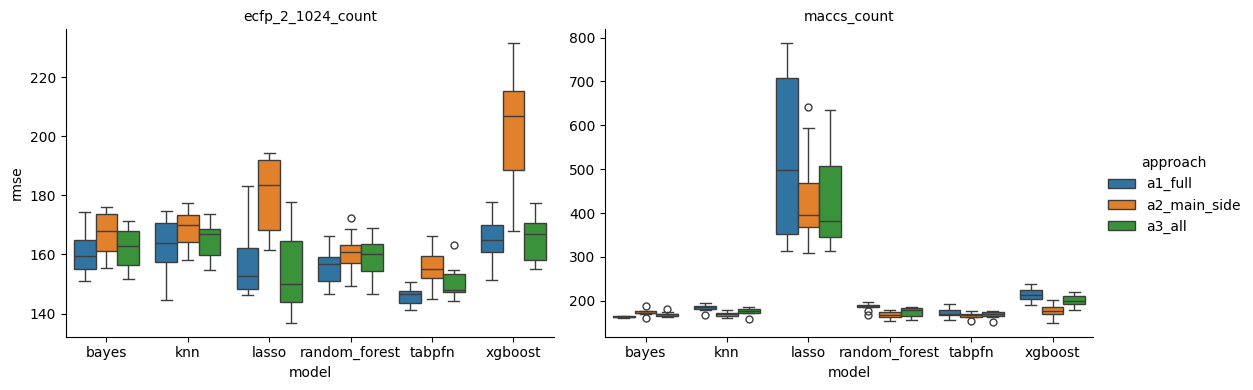

In [5]:
g = sns.catplot(data=per_repeat, x="model", y="rmse", hue="approach", hue_order=APPROACHES, col="representation", kind="box", height=4, aspect=1.4, sharey=False)
g.set_titles("{col_name}")
plt.show()

## Paired comparison vs `a1_full`
Difference in pooled metric per repeat (same folds), Wilcoxon signed-rank over the 10 repeats. Repeats share data, so p-values are optimistic — read them as a sanity check, not as proof.

In [6]:
rows = []
for (model, rep), grp in per_repeat.groupby(["model", "representation"]):
    base = grp[grp["approach"] == "a1_full"].set_index("repeat")
    for approach in APPROACHES[1:]:
        other = grp[grp["approach"] == approach].set_index("repeat")
        for metric in ["rmse", "spearman"]:
            diff = (other[metric] - base[metric]).dropna()
            p = wilcoxon(diff).pvalue if (diff != 0).any() else 1.0
            rows.append({"model": model, "representation": rep, "vs_a1": approach, "metric": metric, "mean_diff": diff.mean(), "p_wilcoxon": p})
paired = pd.DataFrame(rows).round(4)
paired.pivot_table(index=["model", "representation"], columns=["metric", "vs_a1"], values="mean_diff")

metric                                  rmse               spearman        
vs_a1                           a2_main_side    a3_all a2_main_side  a3_all
model         representation                                               
bayes         ecfp_2_1024_count       6.8881    2.0598      -0.0104 -0.0155
              maccs_count            10.5157    5.9372       0.0498  0.0335
knn           ecfp_2_1024_count       6.0195    2.4728      -0.0543  0.0121
              maccs_count           -14.7456   -8.4936       0.3533  0.2486
lasso         ecfp_2_1024_count      23.1609   -3.8493      -0.1240  0.0351
              maccs_count          -100.9909 -106.2538       0.0487  0.0732
random_forest ecfp_2_1024_count       4.5603    2.9742       0.0156 -0.0100
              maccs_count           -18.1019  -11.3007       0.2385  0.1383
tabpfn        ecfp_2_1024_count       9.7536    4.1664      -0.0494 -0.0252
              maccs_count            -4.6723   -3.0044       0.2591  0.1757
xgboost       ecfp_2_1024_count      38.1444    0.7950      -0.1571  0.0114
              maccs_count           -36.4098  -12.1066       0.2098  0.0829

In [7]:
paired.pivot_table(index=["model", "representation"], columns=["metric", "vs_a1"], values="p_wilcoxon")

metric                                  rmse             spearman        
vs_a1                           a2_main_side  a3_all a2_main_side  a3_all
model         representation                                             
bayes         ecfp_2_1024_count       0.0020  0.0371       0.6250  0.2754
              maccs_count             0.0039  0.0098       0.0840  0.0371
knn           ecfp_2_1024_count       0.0488  0.2754       0.3223  0.9219
              maccs_count             0.0020  0.0020       0.0020  0.0020
lasso         ecfp_2_1024_count       0.0020  0.0645       0.0059  0.3223
              maccs_count             0.0371  0.0195       0.1055  0.0840
random_forest ecfp_2_1024_count       0.1055  0.0371       0.8457  0.7695
              maccs_count             0.0020  0.0020       0.0020  0.0020
tabpfn        ecfp_2_1024_count       0.0020  0.0039       0.0098  0.0137
              maccs_count             0.1309  0.3223       0.0020  0.0020
xgboost       ecfp_2_1024_count       0.0020  0.6250       0.0137  0.3223
              maccs_count             0.0020  0.0195       0.0020  0.0098

## Molecules with vs without side chains
On the 18 molecules without side chains the inputs are nearly identical across approaches, so any real effect should show up on the 11 with side chains.

In [8]:
per_repeat_subset = preds.groupby(keys + ["has_side_chain"]).apply(pooled_metrics, include_groups=False).reset_index()
per_repeat_subset.groupby(["has_side_chain", "model", "representation", "approach"])[["rmse", "mae"]].mean().round(1).unstack("approach")

rmse                      \
approach                                       a1_full a2_main_side a3_all   
has_side_chain model         representation                                  
False          bayes         ecfp_2_1024_count   136.7        133.8  133.9   
                             maccs_count         139.8        140.5  141.0   
               knn           ecfp_2_1024_count   139.8        138.6  138.1   
                             maccs_count         156.2        146.6  146.0   
               lasso         ecfp_2_1024_count   137.0        133.5  134.8   
                             maccs_count         345.9        364.8  356.4   
               random_forest ecfp_2_1024_count   118.6        111.0  118.0   
                             maccs_count         167.5        142.2  152.2   
               tabpfn        ecfp_2_1024_count   117.4        115.3  116.1   
                             maccs_count         149.8        136.4  140.3   
               xgboost       ecfp_2_1024_count   142.2        136.2  142.7   
                             maccs_count         209.2        170.5  193.6   
True           bayes         ecfp_2_1024_count   192.4        210.3  200.0   
                             maccs_count         196.9        218.5  208.4   
               knn           ecfp_2_1024_count   194.4        208.7  201.7   
                             maccs_count         223.7        202.5  216.7   
               lasso         ecfp_2_1024_count   185.3        237.8  179.2   
                             maccs_count         728.0        495.8  490.0   
               random_forest ecfp_2_1024_count   202.2        218.2  208.8   
                             maccs_count         214.0        204.2  207.3   
               tabpfn        ecfp_2_1024_count   183.6        205.5  193.5   
                             maccs_count         202.7        207.7  207.0   
               xgboost       ecfp_2_1024_count   196.0        279.4  197.3   
                             maccs_count         218.6        186.8  213.3   

                                                   mae                      
approach                                       a1_full a2_main_side a3_all  
has_side_chain model         representation                                 
False          bayes         ecfp_2_1024_count   100.4         99.5   97.3  
                             maccs_count         117.1        116.7  117.7  
               knn           ecfp_2_1024_count    99.1        100.1   98.0  
                             maccs_count         127.2        112.9  112.5  
               lasso         ecfp_2_1024_count   107.4        102.6  102.9  
                             maccs_count         251.6        259.6  256.8  
               random_forest ecfp_2_1024_count    86.0         74.3   84.6  
                             maccs_count         135.3        107.9  121.0  
               tabpfn        ecfp_2_1024_count    82.5         79.2   80.0  
                             maccs_count         120.9        105.0  110.4  
               xgboost       ecfp_2_1024_count   108.6         99.0  108.3  
                             maccs_count         161.1        130.5  149.1  
True           bayes         ecfp_2_1024_count   164.7        172.4  168.0  
                             maccs_count         157.1        180.9  170.8  
               knn           ecfp_2_1024_count   147.8        157.7  150.1  
                             maccs_count         181.3        152.7  169.3  
               lasso         ecfp_2_1024_count   144.4        175.4  131.4  
                             maccs_count         426.7        297.5  282.0  
               random_forest ecfp_2_1024_count   153.7        162.8  158.5  
                             maccs_count         177.5        159.2  165.6  
               tabpfn        ecfp_2_1024_count   140.0        159.4  149.1  
                             maccs_count         165.6        167.0  166.5  
               xgb

## What the models see — SHAP / coefficient importance per block
Mean |SHAP| per feature over all test rows of all folds (Lasso: mean |coef| on standardized features). Share of total importance per block (`full`, `main`, `side`).

In [9]:
def feature_importance(run_dir: str) -> pd.Series | None:
    columns = pd.read_csv(os.path.join(WORK_DIR, "features", os.path.basename(run_dir) + ".csv"), nrows=0).drop(columns=["capacity_max", "smiles"]).columns
    f_imp = joblib.load(os.path.join(run_dir, "feature_importance.pickle"))
    per_fold = []
    for method, values in f_imp:
        if method is None or values is None or len(values) == 0:
            continue
        if method == "coefficients":
            per_fold.append(pd.Series(np.abs(values["coefficient"][:-1]), index=values["feature"][:-1]))
        else:
            per_fold.append(pd.Series(np.abs(np.asarray(values)).mean(axis=0), index=columns))
    if not per_fold:
        return None
    return pd.concat(per_fold, axis=1).mean(axis=1)


importances = {}
for run_dir in glob(os.path.join(RUNS_DIR, "*", "*")):
    if not os.path.exists(os.path.join(run_dir, "predictions.csv")):
        continue  # unfinished run
    imp = feature_importance(run_dir)
    if imp is not None:
        model = os.path.basename(os.path.dirname(run_dir))
        approach, rep = os.path.basename(run_dir).split("__")
        importances[(model, rep, approach)] = imp

block_share = pd.DataFrame({k: (v.groupby(v.index.str.split("__").str[0]).sum() / v.sum()) for k, v in importances.items()}).T
block_share.index.names = ["model", "representation", "approach"]
block_share.sort_index().round(3)

full   main   side
model         representation    approach                         
bayes         ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.617  0.383
                                a3_all        0.497  0.315  0.188
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.448  0.552
                                a3_all        0.394  0.250  0.356
knn           ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.820  0.180
                                a3_all        0.488  0.418  0.094
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.780  0.220
                                a3_all        0.416  0.430  0.153
lasso         ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.584  0.416
                                a3_all        0.925  0.049  0.026
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.622  0.378
                                a3_all        0.447  0.267  0.286
random_forest ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.706  0.294
                                a3_all        0.576  0.315  0.110
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.643  0.357
                                a3_all        0.500  0.311  0.189
xgboost       ecfp_2_1024_count a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.762  0.238
                                a3_all        0.948  0.047  0.005
              maccs_count       a1_full       1.000    NaN    NaN
                                a2_main_side    NaN  0.680  0.320
                                a3_all        0.830  0.054  0.116

### Top features: does `a1` (full) agree with the `main` block of `a2`?
Same fingerprint bit on full substrate vs main chain → same feature id after stripping the block prefix.

In [10]:
TOP_K = 15
rows = []
for (model, rep, approach), imp in importances.items():
    if approach != "a1_full" or (model, rep, "a2_main_side") not in importances:
        continue
    top_a1 = set(imp.nlargest(TOP_K).index.str.split("__").str[1])
    imp_a2 = importances[(model, rep, "a2_main_side")]
    top_a2 = imp_a2.nlargest(TOP_K)
    top_a2_main = set(top_a2[top_a2.index.str.startswith("main__")].index.str.split("__").str[1])
    rows.append({
        "model": model,
        "representation": rep,
        f"a2 top{TOP_K} from side": int(top_a2.index.str.startswith("side__").sum()),
        f"overlap a1 top{TOP_K} ∩ a2 main": len(top_a1 & top_a2_main),
    })
pd.DataFrame(rows).sort_values(["representation", "model"])

,model,representation,a2 top15 from side,overlap a1 top15 ∩ a2 main
6,bayes,ecfp_2_1024_count,6,7
0,knn,ecfp_2_1024_count,1,9
8,lasso,ecfp_2_1024_count,7,6
4,random_forest,ecfp_2_1024_count,4,9
2,xgboost,ecfp_2_1024_count,6,7
7,bayes,maccs_count,9,6
1,knn,maccs_count,3,9
9,lasso,maccs_count,6,7
5,random_forest,maccs_count,6,9
3,xgboost,maccs_count,3,9


In [11]:
model, rep = "random_forest", "ecfp_2_1024_count"
for approach in APPROACHES:
    if (model, rep, approach) in importances:
        print(approach, importances[(model, rep, approach)].nlargest(10).round(2).to_dict())

a1_full {'full__ecfp_102': 20.7, 'full__ecfp_305': 20.24, 'full__ecfp_675': 13.34, 'full__ecfp_64': 9.24, 'full__ecfp_849': 8.64, 'full__ecfp_34': 8.59, 'full__ecfp_930': 7.73, 'full__ecfp_111': 7.23, 'full__ecfp_62': 6.49, 'full__ecfp_136': 5.66}
a2_main_side {'main__ecfp_305': 24.48, 'main__ecfp_102': 23.87, 'main__ecfp_34': 10.68, 'main__ecfp_930': 9.86, 'side__ecfp_420': 9.75, 'side__ecfp_675': 7.25, 'side__ecfp_64': 5.64, 'main__ecfp_378': 4.88, 'main__ecfp_726': 4.19, 'main__ecfp_849': 3.45}
a3_all {'full__ecfp_675': 12.2, 'main__ecfp_305': 10.89, 'full__ecfp_102': 10.48, 'full__ecfp_305': 10.22, 'main__ecfp_102': 9.61, 'full__ecfp_64': 8.98, 'full__ecfp_849': 7.84, 'full__ecfp_136': 5.35, 'main__ecfp_930': 4.37, 'full__ecfp_111': 4.32}


## Notes
- No hyperparameter tuning (≈23 CTF training samples per fold). Lasso runs with sklearn default `alpha=1.0`, which under-regularizes on MACCS counts — compare it with care.
- TabPFN has no SHAP here (CPU cost); their block importance is missing by design.